In [1]:
!pip install pandas numpy scikit-learn tensorflow matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print(df.head())

Saving dataset.csv to dataset.csv
Dataset shape: (22000, 2)
Column names: ['Text', 'language']
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [3]:
# Identify columns automatically
text_col = next(
    (c for c in df.columns
     if c.lower() in ["text", "sentence", "text_sample"]),
    None
)

label_col = next(
    (c for c in df.columns
     if c.lower() in ["language", "lang", "label"]),
    None
)

print("Text column:", text_col)
print("Language column:", label_col)

if text_col is None or label_col is None:
    raise ValueError(
        "Please check df.columns and set the correct column names."
    )

# Keep only required columns
df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

# Handle missing values
df = df.dropna(subset=["text", "language"])

# Convert to strings and remove extra spaces
df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

# Remove empty text and duplicate examples
df = df[
    (df["text"] != "") &
    (df["language"] != "")
]
df = df.drop_duplicates(subset=["text", "language"])

print("Cleaned dataset shape:", df.shape)
print("Number of languages:", df["language"].nunique())
print(df["language"].value_counts())

Text column: Text
Language column: language
Cleaned dataset shape: (21858, 2)
Number of languages: 22
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [4]:
MAX_PER_LANGUAGE = 500

df = (
    df.groupby("language", group_keys=False)
      .sample(
          n=MAX_PER_LANGUAGE,
          random_state=42,
          replace=False
      )
    if df["language"].value_counts().min() >= MAX_PER_LANGUAGE
    else df.groupby("language", group_keys=False)
           .apply(
               lambda group: group.sample(
                   n=min(len(group), MAX_PER_LANGUAGE),
                   random_state=42
               )
           )
           .reset_index(drop=True)
)

df = df.reset_index(drop=True)

print("Subset shape:", df.shape)
print(df["language"].value_counts())

Subset shape: (11000, 2)
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Encode language labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["language"])

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"].values,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split training data again for validation
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_text,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# Fit tokenizer ONLY on training text
MAX_WORDS = 30000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train_text)

X_train = pad_sequences(
    tokenizer.texts_to_sequences(X_train_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    tokenizer.texts_to_sequences(X_val_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)
print("Language classes:", label_encoder.classes_)

Training shape: (7480, 100)
Validation shape: (1320, 100)
Testing shape: (2200, 100)
Language classes: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']


In [6]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping

NUM_CLASSES = len(label_encoder.classes_)

model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128,
        mask_zero=True
    ),
    SpatialDropout1D(0.2),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.1552 - loss: 2.6525 - val_accuracy: 0.2727 - val_loss: 2.1202
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step - accuracy: 0.4997 - loss: 1.4992 - val_accuracy: 0.6977 - val_loss: 1.0721
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 21s 102ms/step - accuracy: 0.7503 - loss: 0.8232 - val_accuracy: 0.8697 - val_loss: 0.5121
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.8706 - loss: 0.4544 - val_accuracy: 0.8455 - val_loss: 0.5913
Epoch 5/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step - accuracy: 0.8761 - loss: 0.3990 - val_accuracy: 0.8795 - val_loss: 0.4024
Epoch 6/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - accuracy: 0.9158 - loss: 0.2620 - val_accuracy: 0.9045 - val_loss: 0.3221
Epoch 7/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.9360 - loss: 0.1823 - val_accuracy: 0.9189 - val_loss: 0.2804
Epoch 8/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 21s 101ms/step - accuracy: 0.9397 - loss: 0.1

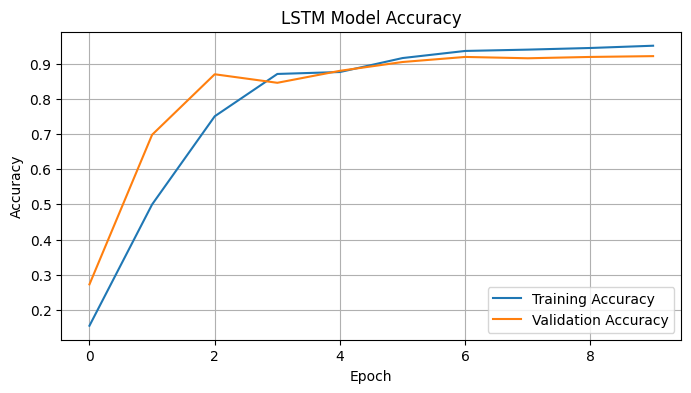

In [8]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    zero_division=0
))

Accuracy : 0.9186
Precision: 0.9215
Recall   : 0.9186
F1-score : 0.9181

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      0.97      0.98       100
     Chinese       0.45      0.58      0.51       100
       Dutch       0.97      1.00      0.99       100
     English       0.93      0.98      0.96       100
    Estonian       0.99      0.95      0.97       100
      French       0.98      0.98      0.98       100
       Hindi       1.00      0.99      0.99       100
  Indonesian       1.00      0.96      0.98       100
    Japanese       0.46      0.30      0.36       100
      Korean       1.00      0.97      0.98       100
       Latin       0.94      0.93      0.93       100
     Persian       1.00      0.99      0.99       100
   Portugese       1.00      0.97      0.98       100
      Pushto       1.00      0.96      0.98       100
    Romanian       1.00      0.95      0.97       100
     Russian       0.98      0.96      

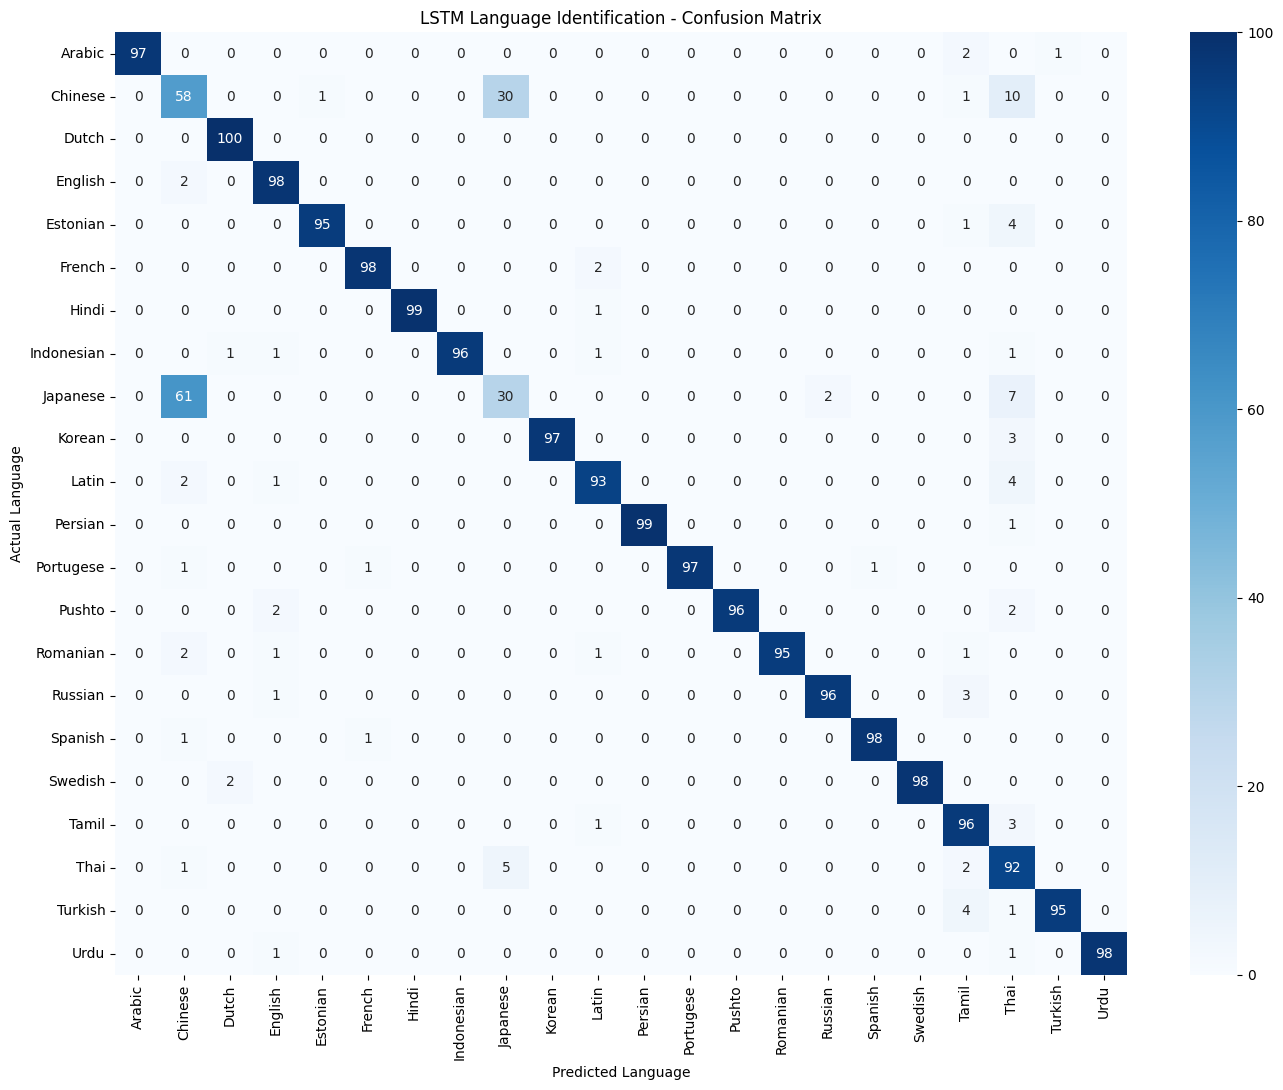

In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("LSTM Language Identification - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
unseen_texts = [
    "The weather is beautiful today.",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "Guten Morgen, wie geht es dir?",
    "Ciao, come stai oggi?"
]

unseen_sequences = tokenizer.texts_to_sequences(unseen_texts)

unseen_padded = pad_sequences(
    unseen_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

probabilities = model.predict(unseen_padded, verbose=0)

predicted_ids = np.argmax(probabilities, axis=1)
confidence = np.max(probabilities, axis=1)

for i, sentence in enumerate(unseen_texts):
    predicted_language = label_encoder.inverse_transform(
        [predicted_ids[i]]
    )[0]

    print(f"\nText: {sentence}")
    print(f"Predicted language: {predicted_language}")
    print(f"Model confidence: {confidence[i]:.2%}")


Text: The weather is beautiful today.
Predicted language: Chinese
Model confidence: 26.82%

Text: Bonjour, comment allez-vous ?
Predicted language: Chinese
Model confidence: 44.59%

Text: Hola, ¿cómo estás?
Predicted language: Japanese
Model confidence: 48.84%

Text: Guten Morgen, wie geht es dir?
Predicted language: Chinese
Model confidence: 37.45%

Text: Ciao, come stai oggi?
Predicted language: Chinese
Model confidence: 49.31%


In [12]:
import pickle

model.save("language_identification_lstm.keras")

with open("language_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("language_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("Model and preprocessing objects saved successfully.")

Model and preprocessing objects saved successfully.


In [13]:
from google.colab import files

files.download("language_identification_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>